In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
import os
import sys
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..', '..')))
from utils_withmoist import dh_func

# Main plot

In [2]:
sol_control=xr.open_dataset("/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/tune_timestep_cesm1_variability_control_cw8pt74_ratio65land600_ensemble_longrun_formultilevel_forcomparisonwithlevelsmay_notikhonov_sst_quarterdt.nc").__xarray_dataarray_variable__
sol_temp=xr.open_dataset("/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/tune_timestep_cesm1_variability_temponly_cw8pt74_ratio65land600_ensemble_longrun_formultilevel_forcomparisonwithlevelsmay_notikhonov_sst_quarterdt.nc").__xarray_dataarray_variable__
sol_tempandice=xr.open_dataset("/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/tune_timestep_cesm1_variability_tempandice_cw8pt74_ratio65land600_ensemble_longrun_formultilevel_forcomparisonwithlevelsmay_notikhonov_sst_quarterdt.nc").__xarray_dataarray_variable__
sol_forced=xr.open_dataset("/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/tune_timestep_cesm1_variability_forced_cw8pt74_ratio65land600_ensemble_longrun_formultilevel_forcomparisonwithlevelsmay_notikhonov_sst_quarterdt.nc").__xarray_dataarray_variable__
control_breakdown=xr.open_dataset("/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/tune_timestep_cesm1_variability_controldecomposition_cw8pt74_ratio65land600_ensemble_longrun_formultilevel_fixmay_notikhonov_sst_quarterdt_updatebdcondboct.nc").__xarray_dataarray_variable__
forced_breakdown=xr.open_dataset("/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/tune_timestep_cesm1_variability_forceddecomposition_cw8pt74_ratio65land600_ensemble_longrun_formultilevel_fixmay_notikhonov_sst_quarterdt_updatebdcondboct.nc").__xarray_dataarray_variable__

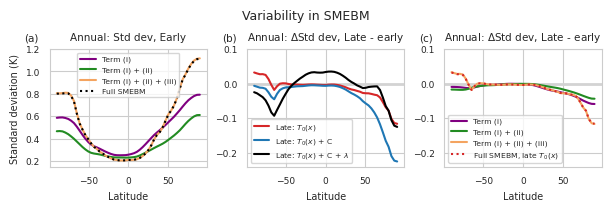

In [3]:
from matplotlib import rcParams

scaling=1/2 #use 1 if half width plot once put into latex. use 1/2 if full width once put into latex
rcParams.update({
    'font.size': 10 * scaling,
    'axes.titlesize': 15 * scaling,
    'axes.labelsize': 14 * scaling,
    'xtick.labelsize': 13 * scaling,
    'ytick.labelsize': 13 * scaling,
    'legend.fontsize': 11 * scaling,
})


fig,((ax1,ax2,ax3))=plt.subplots(1,3,figsize=(6,2),constrained_layout=True)
(control_breakdown[0,:,:,:].std('ensemble_member')[100:,:].mean('time')).plot(ax=ax1,color='purple',label='Term (i)')
(control_breakdown[1,:,:,:].std('ensemble_member')[100:,:].mean('time')).plot(ax=ax1,color='forestgreen',label='Term (i) + (ii)')
(control_breakdown[2,:,:,:].std('ensemble_member')[100:,:].mean('time')).plot(ax=ax1,color='sandybrown',label='Term (i) + (ii) + (iii)')
sol_control.std('ensemble_member')[100:,:].mean('time').plot(ax=ax1,color='black',label='Full SMEBM',linestyle='dotted')

ax1.legend()
ax1.set_title('Annual: Std dev, Early')
ax1.set_ylim([0.15,1.2])
ax1.set_ylabel('Standard deviation (K)')
ax1.set_title('(a)',loc='left',x=-0.16)
ax1.set_xlabel('Latitude')


ax2.axhline(0,color='lightgray',linewidth=2)
(sol_temp.std('ensemble_member')[100:,:].mean('time')-sol_control.std('ensemble_member')[100:,:].mean('time')).plot(ax=ax2,color='tab:red',label='Late: $T_0(x)$')
(sol_tempandice.std('ensemble_member')[100:,:].mean('time')-sol_control.std('ensemble_member')[100:,:].mean('time')).plot(ax=ax2,color='tab:blue',label='Late: $T_0(x)$ + C')
(sol_forced.std('ensemble_member')[100:,:].mean('time')-sol_control.std('ensemble_member')[100:,:].mean('time')).plot(ax=ax2,color='black',label='Late: $T_0(x)$ + C + $\lambda$')
ax2.legend()

ax2.set_ylim([-0.24,0.1])
ax2.set_title(r'Annual: $\Delta$Std dev, Late - early')
ax2.set_ylabel('')
ax2.set_title('(b)',loc='left',x=-0.16)
ax2.set_xlabel('Latitude')




ax3.axhline(0,color='lightgray',linewidth=2)
(forced_breakdown[0,:,:,:].std('ensemble_member')[100:,:].mean('time')-control_breakdown[0,:,:,:].std('ensemble_member')[100:,:].mean('time')).plot(ax=ax3,color='purple',label='Term (i)')
(forced_breakdown[1,:,:,:].std('ensemble_member')[100:,:].mean('time')-control_breakdown[1,:,:,:].std('ensemble_member')[100:,:].mean('time')).plot(ax=ax3,color='forestgreen',label='Term (i) + (ii)')
(forced_breakdown[2,:,:,:].std('ensemble_member')[100:,:].mean('time')-control_breakdown[2,:,:,:].std('ensemble_member')[100:,:].mean('time')).plot(ax=ax3,color='sandybrown',label='Term (i) + (ii) + (iii)')
(sol_temp.std('ensemble_member')[100:,:].mean('time')-sol_control.std('ensemble_member')[100:,:].mean('time')).plot(ax=ax3,color='tab:red',label='Full SMEBM, late $T_0(x)$',linestyle='dotted')
ax3.legend()


ax3.set_ylim([-0.24,0.1])
ax3.set_title(r'Annual: $\Delta$Std dev, Late - early')
ax3.set_ylabel('')
ax3.set_title('(c)',loc='left',x=-0.16)
ax3.set_xlabel('Latitude')







fig.suptitle('Variability in SMEBM',fontsize=18*scaling)

import matplotlib
matplotlib.pyplot.savefig('decomposition_notuniform_fig3_kimnorthparams_updateoct.pdf', dpi=800,bbox_inches='tight',facecolor='white',transparent=False)

# Uniform warming and other designed warming experiments

In [4]:
forced_breakdown_uniform=xr.open_dataset("/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/tune_timestep_cesm1_variability_forceddecomposition_cw8pt74_ratio65land600_ensemble_longrun_formultilevel_fixmay_notikhonov_sst_quarterdt_uniformwarming_updatebdcondboct.nc").__xarray_dataarray_variable__


forced_breakdown_smallPA=xr.open_dataset("/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/tune_timestep_cesm1_variability_forceddecomposition_cw8pt74_ratio65land600_ensemble_longrun_formultilevel_fixmay_notikhonov_sst_quarterdt_smallPAwarming1pt25_updatebdcondboct.nc").__xarray_dataarray_variable__
forced_breakdown_largePA=xr.open_dataset("/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/tune_timestep_cesm1_variability_forceddecomposition_cw8pt74_ratio65land600_ensemble_longrun_formultilevel_fixmay_notikhonov_sst_quarterdt_smallPAwarming10_updatebdcondboct.nc").__xarray_dataarray_variable__


In [5]:
import xesmf as xe

temp_sat=xr.open_dataset('/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/regridded_trefht_40members_CESM1.nc')
temp_sat=temp_sat.__xarray_dataarray_variable__
cesm_temps_mean=temp_sat.mean('ensemble_member')


cesm_temps_mean=cesm_temps_mean.mean('lon')

diff=cesm_temps_mean[-12*25:,:].mean(axis=0)-cesm_temps_mean[12*80:12*105,:].mean(axis=0)
weights = np.cos(np.deg2rad(diff.lat))
weighted_mean = diff.weighted(weights).mean(dim='lat')
print(weighted_mean)

#relative warming equator vs pole
rel_equator = 1
rel_pole = 1.25

abs_lat = np.abs(diff.lat)

# create parabolic shape W_raw = W_equator + (W_pole - W_equator) * (|lat| / 90)^2
raw_parabola = rel_equator + (rel_pole - rel_equator) * (abs_lat / 90.0) ** 2

# get the area-weighted mean of this unscaled parabola
raw_parabola_mean = raw_parabola.weighted(weights).mean(dim='lat')

# Scale it to perfectly match your target data mean
warming_profile = raw_parabola * (weighted_mean / raw_parabola_mean)

# verify
print("Original data weighted mean:       ", float(weighted_mean))
print("Parabolic profile weighted mean:  ", float(warming_profile.weighted(weights).mean(dim='lat')))

<xarray.DataArray '__xarray_dataarray_variable__' ()> Size: 8B
array(3.56264727)
Original data weighted mean:        3.5626472663001447
Parabolic profile weighted mean:   3.5626472663001443


In [6]:
#larger PA
rel_equator = 1
rel_pole = 10

abs_lat = np.abs(diff.lat)


raw_parabola = rel_equator + (rel_pole - rel_equator) * (abs_lat / 90.0) ** 2

raw_parabola_mean = raw_parabola.weighted(weights).mean(dim='lat')

warming_profile_10 = raw_parabola * (weighted_mean / raw_parabola_mean)

# 5. Verify the results
print("Original data weighted mean:       ", float(weighted_mean))
print("Parabolic profile weighted mean:  ", float(warming_profile.weighted(weights).mean(dim='lat')))

Original data weighted mean:        3.5626472663001447
Parabolic profile weighted mean:   3.5626472663001443


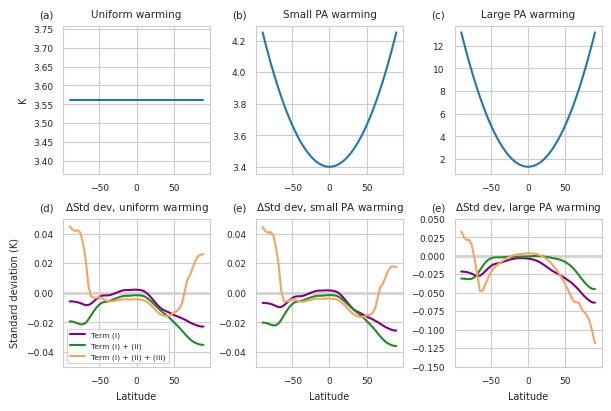

In [7]:
fig,((ax1,ax2,ax3),(ax5,ax6,ax7))=plt.subplots(2,3,figsize=(6,4),constrained_layout=True)

from matplotlib import rcParams

scaling=1/2 #use 1 if half width plot once put into latex. use 1/2 if full width once put into latex
rcParams.update({
    'font.size': 10 * scaling,
    'axes.titlesize': 15 * scaling,
    'axes.labelsize': 14 * scaling,
    'xtick.labelsize': 13 * scaling,
    'ytick.labelsize': 13 * scaling,
    'legend.fontsize': 11 * scaling,
})

(weighted_mean*xr.ones_like(forced_breakdown_uniform[0,:,:,:].std('ensemble_member')[100:,:].mean('time'))).plot(ax=ax1)
ax1.set_xlabel('')
ax1.set_title('Uniform warming')
ax1.set_ylabel('K')
ax1.set_title('(a)',loc='left',x=-0.16)


ax5.axhline(0,color='lightgray',linewidth=2)

(forced_breakdown_uniform[0,:,:,:].std('ensemble_member')[100:,:].mean('time')-control_breakdown[0,:,:,:].std('ensemble_member')[100:,:].mean('time')).plot(ax=ax5,color='purple',label='Term (i)')
(forced_breakdown_uniform[1,:,:,:].std('ensemble_member')[100:,:].mean('time')-control_breakdown[1,:,:,:].std('ensemble_member')[100:,:].mean('time')).plot(ax=ax5,color='forestgreen',label='Term (i) + (ii)')
(forced_breakdown_uniform[2,:,:,:].std('ensemble_member')[100:,:].mean('time')-control_breakdown[2,:,:,:].std('ensemble_member')[100:,:].mean('time')).plot(ax=ax5,color='sandybrown',label='Term (i) + (ii) + (iii)')
ax5.set_ylim([-0.05,0.05])
ax5.set_xlabel('Latitude')
ax5.set_title('$\Delta$Std dev, uniform warming')
ax5.set_ylabel('Standard deviation (K)')
ax5.set_title('(d)',loc='left',x=-0.16)
ax5.legend()



(warming_profile).plot(ax=ax2)
ax2.set_xlabel('')
ax2.set_title('Small PA warming')
ax2.set_ylabel('')
ax2.set_title('(b)',loc='left',x=-0.16)


ax6.axhline(0,color='lightgray',linewidth=2)

(forced_breakdown_smallPA[0,:,:,:].std('ensemble_member')[100:,:].mean('time')-control_breakdown[0,:,:,:].std('ensemble_member')[100:,:].mean('time')).plot(ax=ax6,color='purple',label='Term (i)')
(forced_breakdown_smallPA[1,:,:,:].std('ensemble_member')[100:,:].mean('time')-control_breakdown[1,:,:,:].std('ensemble_member')[100:,:].mean('time')).plot(ax=ax6,color='forestgreen',label='Term (i) + (ii)')
(forced_breakdown_smallPA[2,:,:,:].std('ensemble_member')[100:,:].mean('time')-control_breakdown[2,:,:,:].std('ensemble_member')[100:,:].mean('time')).plot(ax=ax6,color='sandybrown',label='Term (i) + (ii) + (iii)')
ax6.set_ylim([-0.05,0.05])
ax6.set_xlabel('Latitude')
ax6.set_title('$\Delta$Std dev, small PA warming')
ax6.set_ylabel('')
ax6.set_title('(e)',loc='left',x=-0.16)


warming_profile_10.plot(ax=ax3)
ax3.set_xlabel('')
ax3.set_title('Large PA warming')
ax3.set_ylabel('')
ax3.set_title('(c)',loc='left',x=-0.16)



ax7.axhline(0,color='lightgray',linewidth=2)


(forced_breakdown_largePA[0,:,:,:].std('ensemble_member')[100:,:].mean('time')-control_breakdown[0,:,:,:].std('ensemble_member')[100:,:].mean('time')).plot(ax=ax7,color='purple',label='Term (i)')
(forced_breakdown_largePA[1,:,:,:].std('ensemble_member')[100:,:].mean('time')-control_breakdown[1,:,:,:].std('ensemble_member')[100:,:].mean('time')).plot(ax=ax7,color='forestgreen',label='Term (i) + (ii)')
(forced_breakdown_largePA[2,:,:,:].std('ensemble_member')[100:,:].mean('time')-control_breakdown[2,:,:,:].std('ensemble_member')[100:,:].mean('time')).plot(ax=ax7,color='sandybrown',label='Term (i) + (ii) + (iii)')
#ax7.set_ylim([-0.04,0.05])
ax7.set_xlabel('Latitude')
ax7.set_title('$\Delta$Std dev, large PA warming')
ax7.set_ylabel('')
ax7.set_title('(e)',loc='left',x=-0.16)

ax7.set_ylim([-0.15,0.05])




import matplotlib
matplotlib.pyplot.savefig('different_warmingpatterns_idealized_switchcolours_oct2026.pdf', dpi=800,bbox_inches='tight',facecolor='white',transparent=False)

# changing sigma

In [8]:
sol_control=xr.open_dataset("/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/tune_timestep_cesm1_variability_control_cw8pt74_ratio65land600_ensemble_longrun_formultilevel_taylor_noisesigma1_quarterdt.nc").__xarray_dataarray_variable__
sol_noisechange=xr.open_dataset("/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/tune_timestep_cesm1_variability_justchangenoise_cw8pt74_ratio65land600_ensemble_longrun_formultilevel_taylor_noisesigma2_quarterdt.nc").__xarray_dataarray_variable__
sol_noiseandtempchange=xr.open_dataset("/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/tune_timestep_cesm1_variability_changenoiseandtemp_cw8pt74_ratio65land600_ensemble_longrun_formultilevel_taylor_noisesigma2_quarterdt.nc").__xarray_dataarray_variable__
sol_justtempchange=xr.open_dataset("/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/tune_timestep_cesm1_variability_justchangetemp_cw8pt74_ratio65land600_ensemble_longrun_formultilevel_taylor_noisesigma1_quarterdt.nc").__xarray_dataarray_variable__
sol_forcedwithoutnoise=xr.open_dataset("/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/tune_timestep_cesm1_variability_forced_nonoisechange_cw8pt74_ratio65land600_ensemble_longrun_formultilevel_taylor_noisesigma1_quarterdt.nc").__xarray_dataarray_variable__
sol_forcedwithnoise=xr.open_dataset("/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/tune_timestep_cesm1_variability_forced_noisechange_cw8pt74_ratio65land600_ensemble_longrun_formultilevel_taylor_noisesigma2_quarterdt.nc").__xarray_dataarray_variable__


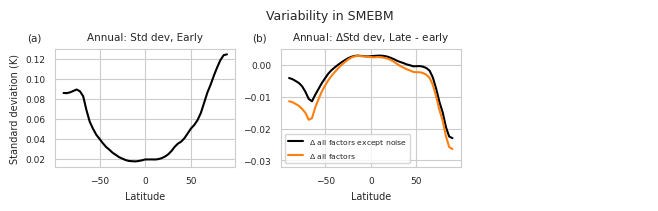

In [9]:
from matplotlib import rcParams

scaling=1/2 #use 1 if half width plot once put into latex. use 1/2 if full width once put into latex
rcParams.update({
    'font.size': 10 * scaling,
    'axes.titlesize': 15 * scaling,
    'axes.labelsize': 14 * scaling,
    'xtick.labelsize': 13 * scaling,
    'ytick.labelsize': 13 * scaling,
    'legend.fontsize': 11 * scaling,
})


fig,((ax1,ax3,ax2))=plt.subplots(1,3,figsize=(6.47,2),constrained_layout=True)

sol_control.std('ensemble_member')[100:,:].mean('time').plot(ax=ax1,color='black')
ax1.set_title('Annual: Std dev, Early')
#ax1.set_ylim([0.1,1.2])
ax1.set_ylabel('Standard deviation (K)')
ax1.set_title('(a)',loc='left',x=-0.16)
ax1.set_xlabel('Latitude')








(sol_forcedwithoutnoise.std('ensemble_member')[100:,:].mean('time')-sol_control.std('ensemble_member')[100:,:].mean('time')).plot(ax=ax3,color='black')
(sol_forcedwithnoise.std('ensemble_member')[100:,:].mean('time')-sol_control.std('ensemble_member')[100:,:].mean('time')).plot(ax=ax3,color='tab:orange')
ax3.legend(['$\Delta$ all factors except noise','$\Delta$ all factors'])

ax3.set_title(r'Annual: $\Delta$Std dev, Late - early')
ax3.set_ylabel('')
ax3.set_title('(b)',loc='left',x=-0.16)
ax3.set_ylim([-0.032,0.005])
ax3.set_xlabel('Latitude')


ax2.axis('off') 

ax2.set_title('')
ax2.set_xlabel('')




fig.suptitle('Variability in SMEBM',fontsize=18*scaling)

import matplotlib
matplotlib.pyplot.savefig('change_noiseinjection_revisedsigma_update_updatedtitle23aug.pdf', dpi=500,bbox_inches='tight',facecolor='white',transparent=False)